# Cell 1 — Setup: Mount Drive & Define Paths

In [ ]:
!pip install -q transformers accelerate bitsandbytes peft

from google.colab import drive
drive.mount('/content/drive')

import os
PROJECT_ROOT = '/content/drive/MyDrive/Bengali Paraphrasing'
PROCESSED_DIR = f'{PROJECT_ROOT}/processed_data'
CHECKPOINT_DIR = f'{PROJECT_ROOT}/checkpoints/qwen2.5'
os.makedirs(f'{CHECKPOINT_DIR}/rolling', exist_ok=True)
os.makedirs(f'{CHECKPOINT_DIR}/best_model', exist_ok=True)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.9/40.9 MB 21.5 MB/s eta 0:00:00
Mounted at /content/drive


# Cell 2 — Download Base Model Files (one-time, direct wget for reliability)

In [ ]:
LOCAL_MODEL_DIR = '/content/qwen_manual_download'
os.makedirs(LOCAL_MODEL_DIR, exist_ok=True)

base_url = "https://huggingface.co/Qwen/Qwen2.5-1.5B-Instruct/resolve/main"
files_needed = [
    "config.json", "generation_config.json", "model.safetensors",
    "tokenizer.json", "tokenizer_config.json", "vocab.json",
    "merges.txt",
]

for fname in files_needed:
    url = f"{base_url}/{fname}"
    out_path = os.path.join(LOCAL_MODEL_DIR, fname)
    print(f"Downloading {fname}...")
    !wget "{url}" -O "{out_path}"

print("\nDone. Files present:")
for fname in os.listdir(LOCAL_MODEL_DIR):
    size = os.path.getsize(os.path.join(LOCAL_MODEL_DIR, fname))
    print(f"  {fname}: {size/(1024*1024):.2f} MB")

--2026-07-27 07:39:19--  https://huggingface.co/Qwen/Qwen2.5-1.5B-Instruct/resolve/main/config.json
Resolving huggingface.co (huggingface.co)... 3.165.160.12, 3.165.160.61, 3.165.160.11, ...
Connecting to huggingface.co (huggingface.co)|3.165.160.12|:443... connected.
HTTP request sent, awaiting response... 307 Temporary Redirect
Location: /api/resolve-cache/models/Qwen/Qwen2.5-1.5B-Instruct/989aa7980e4cf806f80c7fef2b1adb7bc71aa306/config.json?%2FQwen%2FQwen2.5-1.5B-Instruct%2Fresolve%2Fmain%2Fconfig.json=&etag=%22f81ead14ab072d65a07817f83a3ee0e5a1890d10%22 [following]
--2026-07-27 07:39:20--  https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-1.5B-Instruct/989aa7980e4cf806f80c7fef2b1adb7bc71aa306/config.json?%2FQwen%2FQwen2.5-1.5B-Instruct%2Fresolve%2Fmain%2Fconfig.json=&etag=%22f81ead14ab072d65a07817f83a3ee0e5a1890d10%22
Reusing existing connection to huggingface.co:443.
HTTP request sent, awaiting response... 200 OK
Length: 660 [text/plain]
Saving to: ‘/content/qwen_manual

# Cell 3 — Load Model Cache & Tokenizer from Drive, Verify

In [ ]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

BASE_MODEL_CACHE = f'{PROJECT_ROOT}/base_model_cache/qwen2.5'

tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL_CACHE)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True, bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16, bnb_4bit_use_double_quant=True,
)
model = AutoModelForCausalLM.from_pretrained(
    BASE_MODEL_CACHE, quantization_config=bnb_config, device_map={"": 0},
    attn_implementation="sdpa"
)
model = prepare_model_for_kbit_training(model)

lora_config = LoraConfig(
    r=16, lora_alpha=32,
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"],
    lora_dropout=0.05, bias="none", task_type="CAUSAL_LM",
)
model = get_peft_model(model, lora_config)
model.print_trainable_parameters()

MAX_LENGTH = 512
INSTRUCTION = "নিচের বাক্যটি ভিন্নভাবে, একই অর্থ বজায় রেখে লিখুন।"

test = "সেখানেও কিছু জটিলতা আছে।"
check_ids = tokenizer(test, add_special_tokens=False)['input_ids']
assert tokenizer.decode(check_ids, skip_special_tokens=True).strip() == test.strip()
print("Tokenization verified clean, loaded from Drive cache.")

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

trainable params: 18,464,768 || all params: 1,562,179,072 || trainable%: 1.1820
Tokenization verified clean, loaded from Drive cache.


In [ ]:
print("Model's default eos_token_id(s):", model.generation_config.eos_token_id)
print("Tokenizer's eos_token_id:", tokenizer.eos_token_id)

Model's default eos_token_id(s): [151645, 151643]
Tokenizer's eos_token_id: 151645


# Cell 4 — Load Cleaned Dataset (100K subset, same as TigerLLM)

In [ ]:
import pandas as pd
from datasets import Dataset

train_df = pd.read_parquet(os.path.join(PROCESSED_DIR, 'train_subset_100k.parquet'))
val_df = pd.read_parquet(os.path.join(PROCESSED_DIR, 'validation_subset_5k.parquet'))
val_df = val_df.sample(n=500, random_state=42).reset_index(drop=True)  # reduced eval set, lesson from Llama

train_ds = Dataset.from_pandas(train_df[['source', 'target']])
val_ds = Dataset.from_pandas(val_df[['source', 'target']])
print(train_ds, val_ds)

Dataset({
    features: ['source', 'target'],
    num_rows: 100000
}) Dataset({
    features: ['source', 'target'],
    num_rows: 500
})


# Cell 5 — Preprocessing (Chat Template + Label Masking) → Tokenize Dataset

In [ ]:
def preprocess(example):
    messages = [{"role": "user", "content": f"{INSTRUCTION}\n\n{example['source']}"}]
    prompt_text = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    full_text = prompt_text + example['target'] + tokenizer.eos_token

    prompt_ids = tokenizer(prompt_text, add_special_tokens=False)['input_ids']
    full_ids = tokenizer(full_text, add_special_tokens=False, truncation=True, max_length=MAX_LENGTH)['input_ids']

    labels = full_ids.copy()
    prompt_len = min(len(prompt_ids), len(full_ids))
    labels[:prompt_len] = [-100] * prompt_len

    return {'input_ids': full_ids, 'attention_mask': [1] * len(full_ids), 'labels': labels}

train_tok = train_ds.map(preprocess, remove_columns=['source', 'target'])
val_tok = val_ds.map(preprocess, remove_columns=['source', 'target'])
print(train_tok[0])
print("Decoded check:", tokenizer.decode(train_tok[0]['input_ids'], skip_special_tokens=False))

Map:   0%|          | 0/100000 [00:00<?, ? examples/s]

Map:   0%|          | 0/500 [00:00<?, ? examples/s]

{'input_ids': [151644, 8948, 198, 2610, 525, 1207, 16948, 11, 3465, 553, 54364, 14817, 13, 1446, 525, 264, 10950, 17847, 13, 151645, 198, 151644, 872, 198, 86548, 80178, 248, 58908, 72258, 35178, 105, 49128, 243, 52806, 107, 147338, 61356, 35178, 255, 80178, 101, 52806, 101, 148222, 49128, 105, 58908, 11, 35178, 237, 146775, 148868, 35178, 227, 72258, 52806, 98, 35178, 105, 148204, 49128, 107, 11125, 120, 35178, 108, 58908, 149526, 58908, 35178, 110, 80178, 244, 26927, 223, 86548, 146031, 271, 146775, 80178, 101, 52806, 97, 26927, 223, 35178, 101, 147645, 26927, 223, 86548, 35178, 237, 148868, 35178, 246, 148124, 11125, 120, 61356, 35178, 104, 26927, 233, 86548, 35178, 100, 49128, 108, 148194, 49128, 253, 61356, 35178, 97, 149526, 86548, 35178, 105, 49128, 250, 49128, 108, 58908, 35178, 250, 86548, 146838, 52806, 108, 80178, 107, 11125, 120, 35178, 117, 146834, 11125, 120, 86548, 61356, 220, 146031, 151645, 198, 151644, 77091, 198, 146775, 80178, 101, 52806, 97, 26927, 223, 35178, 237,

# Cell 6 — Sanity Check: Confirm Clean Loss (No NaN)

In [ ]:
model.eval()
with torch.no_grad():
    single = train_tok[0]
    input_ids = torch.tensor([single['input_ids']]).to(device)
    attention_mask = torch.tensor([single['attention_mask']]).to(device)
    labels = torch.tensor([single['labels']]).to(device)
    out = model(input_ids=input_ids, attention_mask=attention_mask, labels=labels)
    print("Loss:", out.loss.item(), "| NaN in logits:", torch.isnan(out.logits).any().item())
model.train()

Loss: 0.5667912364006042 | NaN in logits: False


PeftModelForCausalLM(
  (base_model): LoraModel(
    (model): Qwen2ForCausalLM(
      (model): Qwen2Model(
        (embed_tokens): Embedding(151936, 1536)
        (layers): ModuleList(
          (0-27): 28 x Qwen2DecoderLayer(
            (self_attn): Qwen2Attention(
              (q_proj): lora.Linear4bit(
                (base_layer): Linear4bit(in_features=1536, out_features=1536, bias=True)
                (lora_dropout): ModuleDict(
                  (default): Dropout(p=0.05, inplace=False)
                )
                (lora_A): ModuleDict(
                  (default): Linear(in_features=1536, out_features=16, bias=False)
                )
                (lora_B): ModuleDict(
                  (default): Linear(in_features=16, out_features=1536, bias=False)
                )
                (lora_embedding_A): ParameterDict()
                (lora_embedding_B): ParameterDict()
                (lora_magnitude_vector): ModuleDict()
              )
              (k_proj): lora

# Cell 7 — Data Collator

In [ ]:
from dataclasses import dataclass
from typing import List, Dict

@dataclass
class CausalLMPaddingCollator:
    pad_id: int
    def __call__(self, features: List[Dict]):
        def pad_seqs(key, pad_value):
            seqs = [f[key] for f in features]
            max_len = max(len(s) for s in seqs)
            return torch.tensor([s + [pad_value] * (max_len - len(s)) for s in seqs])
        return {
            'input_ids': pad_seqs('input_ids', self.pad_id),
            'attention_mask': pad_seqs('attention_mask', 0),
            'labels': pad_seqs('labels', -100),
        }

collator = CausalLMPaddingCollator(pad_id=tokenizer.pad_token_id)

# Cell 8 — Training Arguments & Trainer Setup

In [ ]:
from transformers import TrainingArguments, Trainer, EarlyStoppingCallback

training_args = TrainingArguments(
    output_dir=f'{CHECKPOINT_DIR}/rolling',
    per_device_train_batch_size=2,
    per_device_eval_batch_size=2,
    gradient_accumulation_steps=8,
    gradient_checkpointing=True,
    gradient_checkpointing_kwargs={"use_reentrant": False},
    fp16=True,
    optim="adamw_torch",
    learning_rate=1e-4,
    weight_decay=0.01,
    max_grad_norm=1.0,
    num_train_epochs=1,
    eval_strategy="steps",
    eval_steps=150,
    save_strategy="steps",
    save_steps=150,
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
    logging_steps=100,
    report_to="none",
)

trainer = Trainer(
    model=model, args=training_args,
    train_dataset=train_tok, eval_dataset=val_tok,
    data_collator=collator,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=3, early_stopping_threshold=0.005)],  # <-- added threshold
)

# Cell 9 — Train (Resume-Aware)

In [ ]:
last_checkpoint = None
rolling_dir = f'{CHECKPOINT_DIR}/rolling'
if os.path.isdir(rolling_dir) and len(os.listdir(rolling_dir)) > 0:
    from transformers.trainer_utils import get_last_checkpoint
    last_checkpoint = get_last_checkpoint(rolling_dir)
    if last_checkpoint:
        print(f"Resuming from checkpoint: {last_checkpoint}")

trainer.train(resume_from_checkpoint=last_checkpoint)

Resuming from checkpoint: /content/drive/MyDrive/Bengali Paraphrasing/checkpoints/qwen2.5/rolling/checkpoint-2250


Step,Training Loss,Validation Loss
2400,0.412757,0.415288
2550,0.413821,0.413355
2700,0.405358,0.411318


TrainOutput(global_step=2700, training_loss=0.0684972169664171, metrics={'train_runtime': 2947.0941, 'train_samples_per_second': 33.932, 'train_steps_per_second': 2.121, 'total_flos': 9.722347512962458e+16, 'train_loss': 0.0684972169664171, 'epoch': 0.432})

# CELL 10: Save Best Model & Clean Up Checkpoints

In [ ]:
best_model_path = f'{CHECKPOINT_DIR}/best_model'
trainer.save_model(best_model_path)
tokenizer.save_pretrained(best_model_path)
print("Best model saved to:", best_model_path)

import shutil
shutil.rmtree(f'{CHECKPOINT_DIR}/rolling')
os.makedirs(f'{CHECKPOINT_DIR}/rolling', exist_ok=True)
print("Rolling checkpoints cleared.")

Best model saved to: /content/drive/MyDrive/Bengali Paraphrasing/checkpoints/qwen2.5/best_model
Rolling checkpoints cleared.


# CELL 11: Loss curve plot

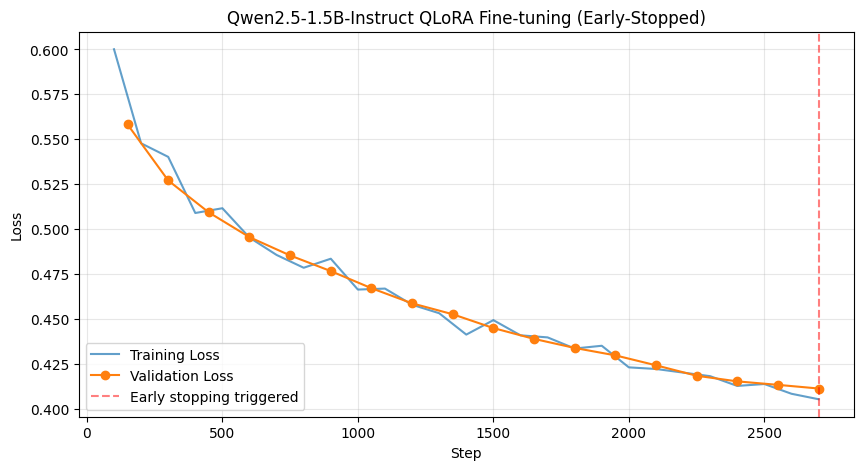

Saved to: /content/drive/MyDrive/Bengali Paraphrasing/checkpoints/qwen2.5/loss_curve.png


In [ ]:
import matplotlib.pyplot as plt

history = trainer.state.log_history
train_steps, train_losses = [], []
eval_steps, eval_losses = [], []

for entry in history:
    if 'loss' in entry and 'eval_loss' not in entry:
        train_steps.append(entry['step'])
        train_losses.append(entry['loss'])
    if 'eval_loss' in entry:
        eval_steps.append(entry['step'])
        eval_losses.append(entry['eval_loss'])

plt.figure(figsize=(10, 5))
plt.plot(train_steps, train_losses, label='Training Loss', alpha=0.7)
plt.plot(eval_steps, eval_losses, label='Validation Loss', marker='o')
plt.axvline(x=2700, color='red', linestyle='--', alpha=0.5, label='Early stopping triggered')
plt.xlabel('Step')
plt.ylabel('Loss')
plt.title('Qwen2.5-1.5B-Instruct QLoRA Fine-tuning (Early-Stopped)')
plt.legend()
plt.grid(alpha=0.3)

plot_path = f'{CHECKPOINT_DIR}/loss_curve.png'
plot_path_svg = f'{CHECKPOINT_DIR}/loss_curve.svg'
plt.savefig(f'{CHECKPOINT_DIR}/loss_curve.png', dpi=150, bbox_inches='tight')  # optional, for quick preview
plt.savefig(f'{CHECKPOINT_DIR}/loss_curve.svg', format='svg', bbox_inches='tight')  # for the paper
plt.show()
print("Saved to:", plot_path)

# CELL 12: Qualitative check — using the same 5 sentences we've tested on every model, for direct comparison

In [ ]:
model.eval()
sample_sources = val_df['source'].sample(5, random_state=42).tolist()

for src in sample_sources:
    messages = [{"role": "user", "content": f"{INSTRUCTION}\n\n{src}"}]
    prompt_text = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = tokenizer(prompt_text, return_tensors="pt").to(device)
    with torch.no_grad():
        output_ids = model.generate(**inputs, max_new_tokens=100, do_sample=False)
    generated = tokenizer.decode(output_ids[0][inputs['input_ids'].shape[1]:], skip_special_tokens=True)
    print(f"SOURCE:    {src}")
    print(f"GENERATED: {generated}")
    print("-" * 60)
model.train()

SOURCE:    এদিকে ভুক্তভোগীদের পরিবারের অভিযোগ, সংঘর্ষ নয়, ওই কিশোরদের বেধড়ক পিটিয়ে হতাহত করা হয়েছে।
GENERATED: এদিকে ভুক্তভোগীদের পরিবারের অভিযোগ, সংঘর্ষ নয়, কিশোরদের দৌরাত্ম্য উন্মুক্ত করা হয়েছে।
------------------------------------------------------------
SOURCE:    বাংলাদেশের কক্সবাজার জেলায় মিয়ানমার সীমান্তবর্তী টেকনাফে এবার ২১জন ইয়াবা ব্যবসায়ীকে ঘটা করে আত্নসমর্পণ করানো হয়েছে।
GENERATED: এই বার বাংলাদেশের কক্সবাজার জেলায় ২১ জন ইয়াবা ব্যবসায়ীকে মায়ানমার সীমান্তে গঠিত টেকনাফে
------------------------------------------------------------
SOURCE:    সাইরাসের সমাধিতে মেসোপটেমীয় বৈশিষ্ট্যপূর্ণ কক্ষের দেখা পাওয়া যায়।
GENERATED: সাইরাসের সমাহিতে মেসোপটেমীয় বৈশিষ্ট্যপূর্ণ ঘরগুলি দেখা যায়।
------------------------------------------------------------
SOURCE:    ফলে লিসার জীবন হয়ে ওঠে অভাব পীড়িত।
GENERATED: এর ফলে লিসার তার জীবন অভাবে পীড়ে গিয়েছিল।
------------------------------------------------------------
SOURCE:    মিশরীয় ও হিব্রুদের সাথেও তাদের ব্যবসায়িক সম্পর্ক 

PeftModelForCausalLM(
  (base_model): LoraModel(
    (model): Qwen2ForCausalLM(
      (model): Qwen2Model(
        (embed_tokens): Embedding(151936, 1536)
        (layers): ModuleList(
          (0-27): 28 x Qwen2DecoderLayer(
            (self_attn): Qwen2Attention(
              (q_proj): lora.Linear4bit(
                (base_layer): Linear4bit(in_features=1536, out_features=1536, bias=True)
                (lora_dropout): ModuleDict(
                  (default): Dropout(p=0.05, inplace=False)
                )
                (lora_A): ModuleDict(
                  (default): Linear(in_features=1536, out_features=16, bias=False)
                )
                (lora_B): ModuleDict(
                  (default): Linear(in_features=16, out_features=1536, bias=False)
                )
                (lora_embedding_A): ParameterDict()
                (lora_embedding_B): ParameterDict()
                (lora_magnitude_vector): ModuleDict()
              )
              (k_proj): lora

# CELL 13: Training summary JSON

In [ ]:
import json

training_summary = {
    "model": "Qwen/Qwen2.5-1.5B-Instruct",
    "method": "QLoRA (4-bit, LoRA r=16, alpha=32, sdpa attention)",
    "dataset": "BanglaParaphrase subset (100,000 train pairs) - same subset as TigerLLM",
    "max_length": 512,
    "planned_epochs": 1,
    "actual_stop": "Early stopped at step 2700 (43% of planned 6250 steps)",
    "early_stopping_rule": "patience=3, threshold=0.005 (three consecutive evals with <0.005 improvement)",
    "final_validation_loss": 0.411318,
    "note": "Early stopping confirms teacher's methodological argument that 1 epoch (and often less) is sufficient for instruction-tuned LLM alignment to a downstream task, avoiding overfitting/diversity loss.",
}

summary_path = f'{CHECKPOINT_DIR}/training_summary.json'
with open(summary_path, 'w', encoding='utf-8') as f:
    json.dump(training_summary, f, ensure_ascii=False, indent=2)
print(json.dumps(training_summary, ensure_ascii=False, indent=2))

{
  "model": "Qwen/Qwen2.5-1.5B-Instruct",
  "method": "QLoRA (4-bit, LoRA r=16, alpha=32, sdpa attention)",
  "dataset": "BanglaParaphrase subset (100,000 train pairs) - same subset as TigerLLM",
  "max_length": 512,
  "planned_epochs": 1,
  "actual_stop": "Early stopped at step 2700 (43% of planned 6250 steps)",
  "early_stopping_rule": "patience=3, threshold=0.005 (three consecutive evals with <0.005 improvement)",
  "final_validation_loss": 0.411318,
  "note": "Early stopping confirms teacher's methodological argument that 1 epoch (and often less) is sufficient for instruction-tuned LLM alignment to a downstream task, avoiding overfitting/diversity loss."
}


# CELL 14: Reload verification

In [ ]:
from transformers import AutoTokenizer, AutoModelForCausalLM
from peft import PeftModel

verify_tokenizer = AutoTokenizer.from_pretrained(best_model_path)
base_verify = AutoModelForCausalLM.from_pretrained(BASE_MODEL_CACHE, quantization_config=bnb_config, device_map={"": 0})
verify_model = PeftModel.from_pretrained(base_verify, best_model_path)
print("Reload check passed -- Qwen2.5 best_model/ is complete and loadable independently.")

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Reload check passed -- Qwen2.5 best_model/ is complete and loadable independently.


In [ ]:
import json
history_path = f'{CHECKPOINT_DIR}/log_history.json'
with open(history_path, 'w') as f:
    json.dump(trainer.state.log_history, f, indent=2)
print("Saved raw training history to:", history_path)